# Fase C — Modelos predictivos (supervisados y no supervisado)

**Proyecto:** Introducción a la Ciencia de Datos · Hurtos por modalidades (Policía Nacional)

**Pregunta de negocio:** ¿es posible predecir la cantidad de hurtos de **motocicletas** que se presentarán en un **municipio** durante el **siguiente mes**, utilizando el comportamiento histórico de los hurtos y las variables disponibles en el dataset?

**Tipo de problema:** regresión (el objetivo es un número: cuántas motos se hurtan).

**Modelos:**
1. Regresión Lineal (el modelo simple y fácil de interpretar)
2. Gradient Boosting (el modelo más flexible, que aprende patrones no lineales)
3. Random Forest Regressor (muchos árboles independientes promediados; robusto a valores atípicos)
4. K-Means (no supervisado): segmentación de los municipios según su perfil de hurto

**Reglas que cumple este notebook**
- Se usa `train_test_split` (80/20) y **todas las métricas se calculan sobre el conjunto de prueba (test)**.
- **No se normaliza antes del split.** El escalado se ajusta solo con los datos de entrenamiento (dentro de un `Pipeline`), para evitar *data leakage*.
- Nunca se evalúa con las mismas filas con las que se entrenó.

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, silhouette_score, davies_bouldin_score

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
SEMILLA = 42   # misma semilla en todo el notebook -> resultados reproducibles

## 1. Carga de datos

Cargamos `datos_limpios.parquet` (resultado de la fase de limpieza). Cada fila es **un municipio en un mes**.
Ordenamos por municipio y fecha para que el orden temporal sea el correcto.


In [2]:
from pathlib import Path
import pandas as pd
import numpy as np

# Ajusta la ruta si tu archivo está en otra carpeta
RUTAS = ["datos_limpios.parquet", "datos/datos_limpios.parquet", "../datos/datos_limpios.parquet"]
ruta = next((r for r in RUTAS if Path(r).exists()), None)
if ruta is None:
    raise FileNotFoundError(f"No encuentro datos_limpios.parquet. Carpeta actual: {Path.cwd()}")

df = (pd.read_parquet(ruta)
        .sort_values(["LLAVE_MUN", "FECHA_MES"])
        .reset_index(drop=True))

print(f"Dataset: {df.shape[0]:,} filas x {df.shape[1]} columnas")
print(f"Municipios: {df['LLAVE_MUN'].nunique():,} | Periodo: {df['FECHA_MES'].min():%Y-%m} a {df['FECHA_MES'].max():%Y-%m}")
print(f"Valores nulos: {int(df.isna().sum().sum())}")
df[["LLAVE_MUN", "FECHA_MES", "MOTOS", "MOTOS_LAG1", "MOTOS_PROM3", "MOTOS_LAG12"]].head()

Dataset: 182,350 filas x 64 columnas
Municipios: 1,042 | Periodo: 2012-01 a 2026-07
Valores nulos: 0


,LLAVE_MUN,FECHA_MES,MOTOS,MOTOS_LAG1,MOTOS_PROM3,MOTOS_LAG12
0,AMAZONAS | LETICIA,2012-01-01,1,3.0,1.333333,4.0
1,AMAZONAS | LETICIA,2012-02-01,1,1.0,1.333333,2.0
2,AMAZONAS | LETICIA,2012-03-01,1,1.0,1.666667,1.0
3,AMAZONAS | LETICIA,2012-04-01,2,1.0,1.000000,2.0
4,AMAZONAS | LETICIA,2012-05-01,1,2.0,1.333333,1.0


## 2. Variable objetivo y variables predictoras

**Variable objetivo:** `MOTOS` = hurtos de motocicletas del municipio en el mes que queremos predecir.

**Idea clave para "predecir el siguiente mes":** cada fila representa un mes `t`. Las variables predictoras solo pueden usar información **que ya se conocía antes de que empezara ese mes**:

| Variable | Qué es | ¿Se conoce antes del mes `t`? |
|---|---|---|
| `MOTOS_LAG1` | hurtos de motos del mes anterior | sí |
| `MOTOS_PROM3` | promedio de los 3 meses anteriores | sí |
| `MOTOS_LAG12` | hurtos del mismo mes un año atrás | sí |
| `AUTOS_LAG1` | hurtos de autos del mes anterior | sí |
| `ANIO`, `MES_*` | calendario |sí |
| `DEPARTAMENTO_*`, `ES_CAPITAL_CT` | ubicación del municipio | sí |

**Columnas que NO usamos (y por qué):**
- `MOTOS_LOG`: es el mismo objetivo transformado con logaritmo → daría la respuesta al modelo (*fuga de información*).
- `AUTOS`, `AUTOS_LOG`: hurtos de autos del **mismo** mes, que no conoceríamos al predecir.
- `*_ESC` (variables ya estandarizadas): fueron escaladas con otra partición de los datos. Para cumplir la regla de **no normalizar antes del split**, usamos las variables originales y escalamos después, solo con el train.
- `LLAVE_MUN`, `FECHA_MES`, `CONJUNTO`: identificadores / etiquetas, no son variables predictoras.

In [3]:
TARGET = "MOTOS"

# Verificación anti-fuga: los rezagos deben venir realmente de meses anteriores
g = df.groupby("LLAVE_MUN")[TARGET]
mismo_mun = df["LLAVE_MUN"].eq(df["LLAVE_MUN"].shift(1))
assert (g.shift(1)[mismo_mun] == df["MOTOS_LAG1"][mismo_mun]).all(), "LAG1 no coincide"
prom3 = g.transform(lambda s: s.shift(1).rolling(3).mean())
assert np.allclose(prom3.dropna(), df.loc[prom3.notna(), "MOTOS_PROM3"]), "PROM3 no coincide"
print("Los rezagos usan solo meses anteriores (sin fuga del mes a predecir).")

EXCLUIR = (["LLAVE_MUN", "FECHA_MES", "CONJUNTO", TARGET, "MOTOS_LOG", "AUTOS", "AUTOS_LOG"]
           + [c for c in df.columns if c.endswith("_ESC")])

X = df.drop(columns=EXCLUIR)
y = df[TARGET]

print(f"X: {X.shape[0]:,} filas x {X.shape[1]} variables predictoras")
print(f"y ({TARGET}): media={y.mean():.2f} | mediana={y.median():.0f} | máx={y.max()} | % de meses con 0 hurtos={(y==0).mean():.1%}")

Los rezagos usan solo meses anteriores (sin fuga del mes a predecir).
X: 182,350 filas x 53 variables predictoras
y (MOTOS): media=2.54 | mediana=0 | máx=658 | % de meses con 0 hurtos=70.1%


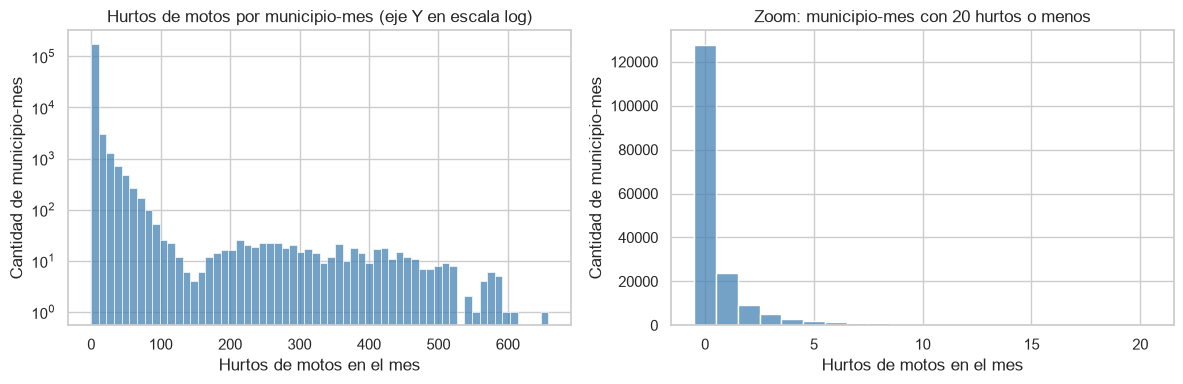

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(y, bins=60, ax=axes[0], color="steelblue")
axes[0].set_yscale("log")
axes[0].set_title("Hurtos de motos por municipio-mes (eje Y en escala log)")
axes[0].set_xlabel("Hurtos de motos en el mes"); axes[0].set_ylabel("Cantidad de municipio-mes")
sns.histplot(y[y <= 20], bins=21, discrete=True, ax=axes[1], color="steelblue")
axes[1].set_title("Zoom: municipio-mes con 20 hurtos o menos")
axes[1].set_xlabel("Hurtos de motos en el mes"); axes[1].set_ylabel("Cantidad de municipio-mes")
plt.tight_layout(); plt.show()

**Insight:** la mayoría de municipio-mes tiene 0 o muy pocos hurtos, y unas pocas ciudades grandes tienen cientos. Es una distribución muy sesgada. Esto importa porque los errores en las ciudades grandes pesan mucho más en el **RMSE** que en el **MAE**.

## 3. Split Entrenamiento / Prueba (80 / 20)

El split se hace **antes** de cualquier escalado.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEMILLA
)

print(f"Train: {len(X_train):,} filas ({len(X_train)/len(X):.0%}) | Test: {len(X_test):,} filas ({len(X_test)/len(X):.0%})")
assert set(X_train.index).isdisjoint(X_test.index), "¡Hay filas repetidas entre train y test!"
print("Ninguna fila está en train y test a la vez.")

Train: 145,880 filas (80%) | Test: 36,470 filas (20%)
Ninguna fila está en train y test a la vez.


## 4. Punto de comparación (baseline)

Antes de entrenar, necesitamos saber **cuánto es "buen resultado"**. El baseline más simple: *"el próximo mes habrá los mismos hurtos que el mes pasado"* (`MOTOS_LAG1`). Si un modelo no supera esto, no aporta valor.

**Métricas** :

| Métrica | Qué significa | Ideal |
|---|---|---|
| **MAE** | error promedio, en "motos hurtadas" | cercano a 0 |
| **MSE** | promedio de los errores al cuadrado (en "motos²"); castiga mucho los errores grandes | cercano a 0 |
| **RMSE** | como el MAE pero castiga más los errores grandes | cercano a 0 |
| **R²** | % de la variación que el modelo logra explicar | cercano a 1 |

In [6]:
def evaluar(nombre, y_real, y_pred):
    """Calcula las métricas de regresión. Siempre se llama con datos de TEST."""
    return {
        "Modelo": nombre,
        "MAE":  round(mean_absolute_error(y_real, y_pred), 4),
        "MSE":  round(mean_squared_error(y_real, y_pred), 4),
        "RMSE": round(np.sqrt(mean_squared_error(y_real, y_pred)), 4),
        "R²":   round(r2_score(y_real, y_pred), 4),
    }

resultados = [evaluar("Baseline (mes anterior)", y_test, X_test["MOTOS_LAG1"])]
pd.DataFrame(resultados)

,Modelo,MAE,MSE,RMSE,R²
0,Baseline (mes anterior),0.9148,12.7618,3.5724,0.9667


## 5. Modelo 1 — Regresión Lineal

**Idea:** busca la mejor "receta" que suma los aportes de cada variable:

`hurtos ≈ β₀ + β₁·(hurtos mes anterior) + β₂·(promedio 3 meses) + β₃·(mismo mes año pasado) + ... + (efecto departamento) + (efecto mes)`

Cada coeficiente dice cuántos hurtos suben (o bajan) por cada unidad que sube esa variable, manteniendo lo demás constante.

**Sobre el escalado:** la regresión lineal no lo necesita para predecir, pero lo usamos para poder **comparar coeficientes** entre variables. Lo metemos dentro de un `Pipeline`: así el `StandardScaler` se ajusta **solo con X_train** y luego se aplica a X_test. Esto evita el data leakage.

In [7]:
modelo_lineal = Pipeline([
    ("escalador", StandardScaler()),          # se ajusta SOLO con train
    ("regresion", LinearRegression()),
])

modelo_lineal.fit(X_train, y_train)           # aprende con train
y_pred_lin = modelo_lineal.predict(X_test)    # predice en test (datos nunca vistos)

# La regresión lineal puede dar valores negativos; no existen "hurtos negativos"
y_pred_lin_0 = np.clip(y_pred_lin, 0, None)

resultados.append(evaluar("Regresión Lineal", y_test, y_pred_lin))
resultados.append(evaluar("Regresión Lineal (pred. ≥ 0)", y_test, y_pred_lin_0))
print(pd.DataFrame(resultados).to_string(index=False))
print(f"\nPredicciones negativas de la regresión lineal: {(y_pred_lin < 0).mean():.1%} de test")

                      Modelo    MAE     MSE   RMSE     R²
     Baseline (mes anterior) 0.9148 12.7618 3.5724 0.9667
            Regresión Lineal 0.8589  9.7062 3.1155 0.9747
Regresión Lineal (pred. ≥ 0) 0.8467  9.7032 3.1150 0.9747

Predicciones negativas de la regresión lineal: 16.3% de test


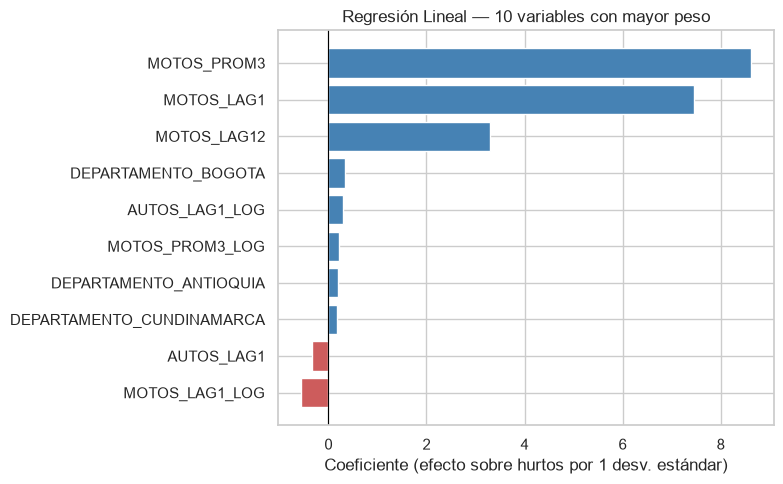

In [8]:
# Variables con mayor peso (coeficientes sobre variables estandarizadas -> son comparables)
coefs = pd.Series(modelo_lineal.named_steps["regresion"].coef_, index=X.columns)
top = coefs.reindex(coefs.abs().sort_values(ascending=False).index).head(10).sort_values()

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top.index, top.values, color=np.where(top.values >= 0, "steelblue", "indianred"))
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Regresión Lineal — 10 variables con mayor peso")
ax.set_xlabel("Coeficiente (efecto sobre hurtos por 1 desv. estándar)")
plt.tight_layout(); plt.show()

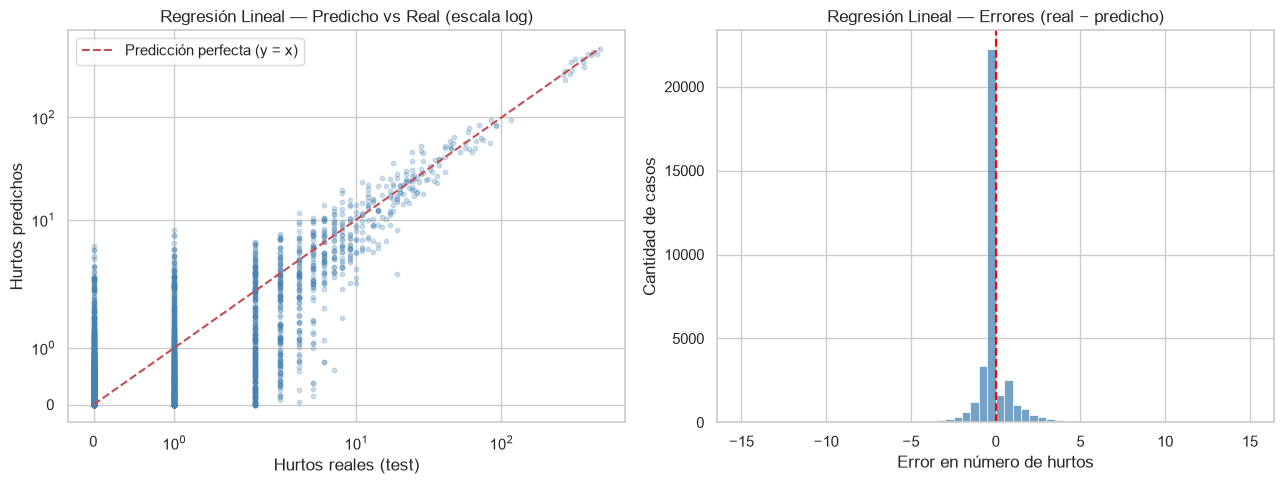

In [9]:
def grafico_pred_vs_real(y_real, y_pred, titulo):
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    rng = np.random.default_rng(SEMILLA)
    idx = rng.choice(len(y_real), 5000, replace=False)
    yr, yp = np.asarray(y_real)[idx], np.asarray(y_pred)[idx]

    axes[0].scatter(yr, yp, alpha=0.25, s=10, color="steelblue")
    lim = [min(yr.min(), yp.min()), max(yr.max(), yp.max())]
    axes[0].plot(lim, lim, "r--", label="Predicción perfecta (y = x)")
    axes[0].set_xscale("symlog"); axes[0].set_yscale("symlog")
    axes[0].set_xlabel("Hurtos reales (test)"); axes[0].set_ylabel("Hurtos predichos")
    axes[0].set_title(f"{titulo} — Predicho vs Real (escala log)")
    axes[0].legend()

    errores = np.asarray(y_real) - np.asarray(y_pred)
    sns.histplot(errores[np.abs(errores) <= 15], bins=60, ax=axes[1], color="steelblue")
    axes[1].axvline(0, color="red", linestyle="--")
    axes[1].set_title(f"{titulo} — Errores (real − predicho)")
    axes[1].set_xlabel("Error en número de hurtos"); axes[1].set_ylabel("Cantidad de casos")
    plt.tight_layout(); plt.show()

grafico_pred_vs_real(y_test, y_pred_lin_0, "Regresión Lineal")

**Insight:** si los puntos siguen la línea roja, el modelo acierta. Los errores se concentran alrededor de 0 (la mayoría de municipios tiene pocos hurtos y se predicen bien). Los desvíos más grandes ocurren en municipios con muchos hurtos.

## 6. Modelo 2 — Gradient Boosting

**Ventajas frente a la lineal:** captura relaciones **no lineales** (por ejemplo, que el efecto del mes anterior no sea igual en un pueblo pequeño que en Bogotá) y no necesita escalado.
**Desventajas:** menos interpretable y más lento de entrenar.

**Hiperparámetros elegidos:**
- `n_estimators=200` → número de árboles.
- `learning_rate=0.1` → qué tanto corrige cada árbol (más bajo = más cauteloso).
- `max_depth=4` → profundidad de cada árbol; árboles pequeños evitan memorizar.
- `subsample=0.8` → cada árbol ve el 80% de las filas (reduce sobreajuste).



In [10]:
modelo_gb = GradientBoostingRegressor(
    n_estimators=200,
    learning_rate=0.1,
    max_depth=4,
    subsample=0.8,
    random_state=SEMILLA,
)

modelo_gb.fit(X_train, y_train)               # aprende con train
y_pred_gb = modelo_gb.predict(X_test)         # predice en test
y_pred_gb_0 = np.clip(y_pred_gb, 0, None)

resultados.append(evaluar("Gradient Boosting", y_test, y_pred_gb))
resultados.append(evaluar("Gradient Boosting (pred. ≥ 0)", y_test, y_pred_gb_0))
print(pd.DataFrame(resultados).to_string(index=False))

                       Modelo    MAE     MSE   RMSE     R²
      Baseline (mes anterior) 0.9148 12.7618 3.5724 0.9667
             Regresión Lineal 0.8589  9.7062 3.1155 0.9747
 Regresión Lineal (pred. ≥ 0) 0.8467  9.7032 3.1150 0.9747
            Gradient Boosting 0.8738 11.7106 3.4221 0.9695
Gradient Boosting (pred. ≥ 0) 0.8738 11.7106 3.4221 0.9695


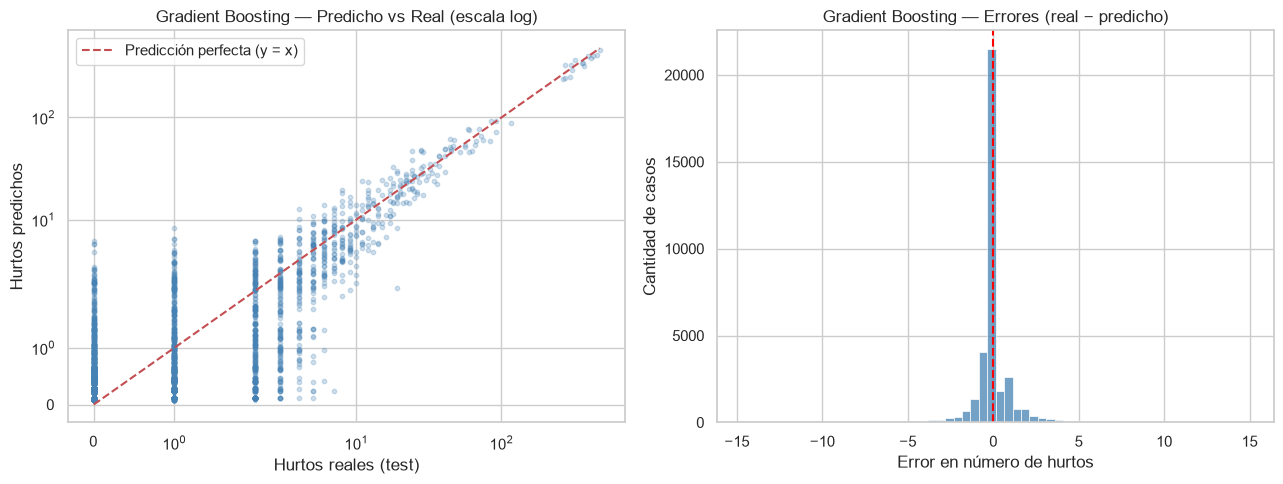

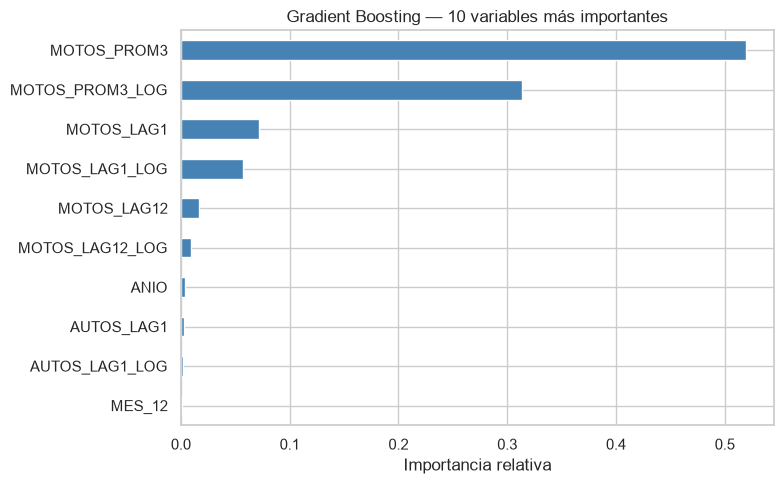

In [11]:
grafico_pred_vs_real(y_test, y_pred_gb_0, "Gradient Boosting")

imp = pd.Series(modelo_gb.feature_importances_, index=X.columns).sort_values().tail(10)
fig, ax = plt.subplots(figsize=(8, 5))
imp.plot.barh(ax=ax, color="steelblue")
ax.set_title("Gradient Boosting — 10 variables más importantes")
ax.set_xlabel("Importancia relativa")
plt.tight_layout(); plt.show()

**Insight:** las variables que más usa el modelo son las del **comportamiento histórico reciente** (promedio de 3 meses y mes anterior). El departamento y el mes del año aportan muy poco. En otras palabras: *para predecir los hurtos del próximo mes, lo más informativo es mirar cómo vienen los últimos meses.*

## 7. Modelo 3 — Random Forest Regressor

**Idea:** entrena **muchos árboles de decisión**, cada uno con una muestra distinta de filas y de variables, y **promedia** sus predicciones. Un árbol solo memoriza fácilmente; el promedio de muchos árboles distintos es mucho más estable.

**Diferencia con Gradient Boosting:** en Gradient Boosting los árboles se construyen **en cadena** (cada uno corrige el error del anterior); en Random Forest se construyen **en paralelo e independientes**. Por eso Random Forest es menos sensible a los hiperparámetros y a los valores atípicos (las ciudades grandes), y tampoco necesita escalado.

**Hiperparámetros elegidos:**
- `n_estimators=200` → número de árboles que se promedian.
- `min_samples_leaf=5` → cada hoja necesita al menos 5 municipio-mes; evita reglas basadas en un solo caso (sobreajuste).
- `max_features=0.5` → cada división considera la mitad de las variables; hace los árboles más diferentes entre sí.
- `n_jobs=-1` → usa todos los núcleos del computador para entrenar más rápido.

In [12]:
modelo_rf = RandomForestRegressor(
    n_estimators=200,
    min_samples_leaf=5,
    max_features=0.5,
    n_jobs=-1,
    random_state=SEMILLA,
)

modelo_rf.fit(X_train, y_train)               # aprende con train
y_pred_rf = modelo_rf.predict(X_test)         # predice en test
# Un promedio de árboles nunca predice negativos, así que no hace falta recortar en 0

resultados.append(evaluar("Random Forest", y_test, y_pred_rf))
print(pd.DataFrame(resultados).to_string(index=False))

# Control de sobreajuste: comparamos el error en train con el de test (solo informativo, NO es la evaluación)
mae_train_rf = mean_absolute_error(y_train, modelo_rf.predict(X_train))
print(f"\nMAE en train: {mae_train_rf:.4f} | MAE en test: {mean_absolute_error(y_test, y_pred_rf):.4f}")

                       Modelo    MAE     MSE   RMSE     R²
      Baseline (mes anterior) 0.9148 12.7618 3.5724 0.9667
             Regresión Lineal 0.8589  9.7062 3.1155 0.9747
 Regresión Lineal (pred. ≥ 0) 0.8467  9.7032 3.1150 0.9747
            Gradient Boosting 0.8738 11.7106 3.4221 0.9695
Gradient Boosting (pred. ≥ 0) 0.8738 11.7106 3.4221 0.9695
                Random Forest 0.8530 10.1107 3.1797 0.9736

MAE en train: 0.7051 | MAE en test: 0.8530


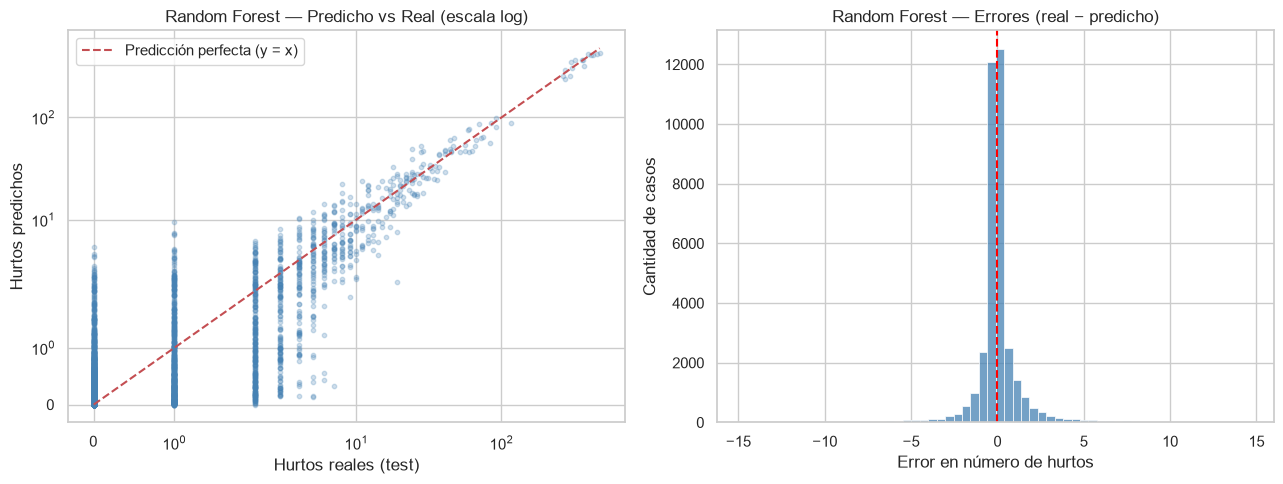

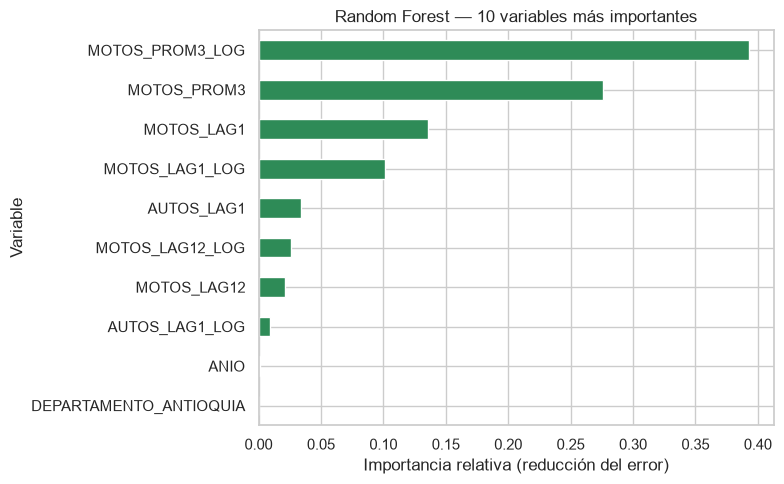

Importancia acumulada de las variables de historia (8 columnas): 99.7%
Importancia acumulada de calendario y ubicación (ANIO, MES_*, DEPARTAMENTO_*, ES_CAPITAL_CT): 0.3%


In [13]:
grafico_pred_vs_real(y_test, y_pred_rf, "Random Forest")

imp_rf = pd.Series(modelo_rf.feature_importances_, index=X.columns).sort_values().tail(10)
fig, ax = plt.subplots(figsize=(8, 5))
imp_rf.plot.barh(ax=ax, color="seagreen")
ax.set_title("Random Forest — 10 variables más importantes")
ax.set_xlabel("Importancia relativa (reducción del error)")
ax.set_ylabel("Variable")
plt.tight_layout(); plt.show()
imp_todas = pd.Series(modelo_rf.feature_importances_, index=X.columns)
historia = [c for c in X.columns if "LAG" in c or "PROM" in c]       # rezagos y promedios (normales y en log)
print(f"Importancia acumulada de las variables de historia ({len(historia)} columnas): {imp_todas[historia].sum():.1%}")
print(f"Importancia acumulada de calendario y ubicación (ANIO, MES_*, DEPARTAMENTO_*, ES_CAPITAL_CT): {imp_todas.drop(historia).sum():.1%}")

**Insight:** Random Forest logra un **MAE de 0,853** en test, mejor que Gradient Boosting (0,874) y muy cerca de la Regresión Lineal (0,847). Casi toda su "inteligencia" sale del **historial reciente**: las variables de rezago y promedio (en escala normal y log) concentran el **99,7 % de la importancia**, y el promedio de los 3 meses anteriores es la más usada. El calendario y el departamento juntos aportan solo el 0,3 %. El MAE en train (0,705) es algo menor que en test (0,853): hay un sobreajuste leve, controlado por `min_samples_leaf=5`, y el modelo generaliza bien. A diferencia de la lineal, **nunca predice hurtos negativos**.

## 8. Comparación final de modelos (sobre test)

,Modelo,MAE,MSE,RMSE,R²,Mejora MAE vs baseline
0,Baseline (mes anterior),0.9148,12.7618,3.5724,0.9667,0.0%
1,Regresión Lineal (pred. ≥ 0),0.8467,9.7032,3.1150,0.9747,7.4%
2,Gradient Boosting (pred. ≥ 0),0.8738,11.7106,3.4221,0.9695,4.5%
3,Random Forest,0.8530,10.1107,3.1797,0.9736,6.8%


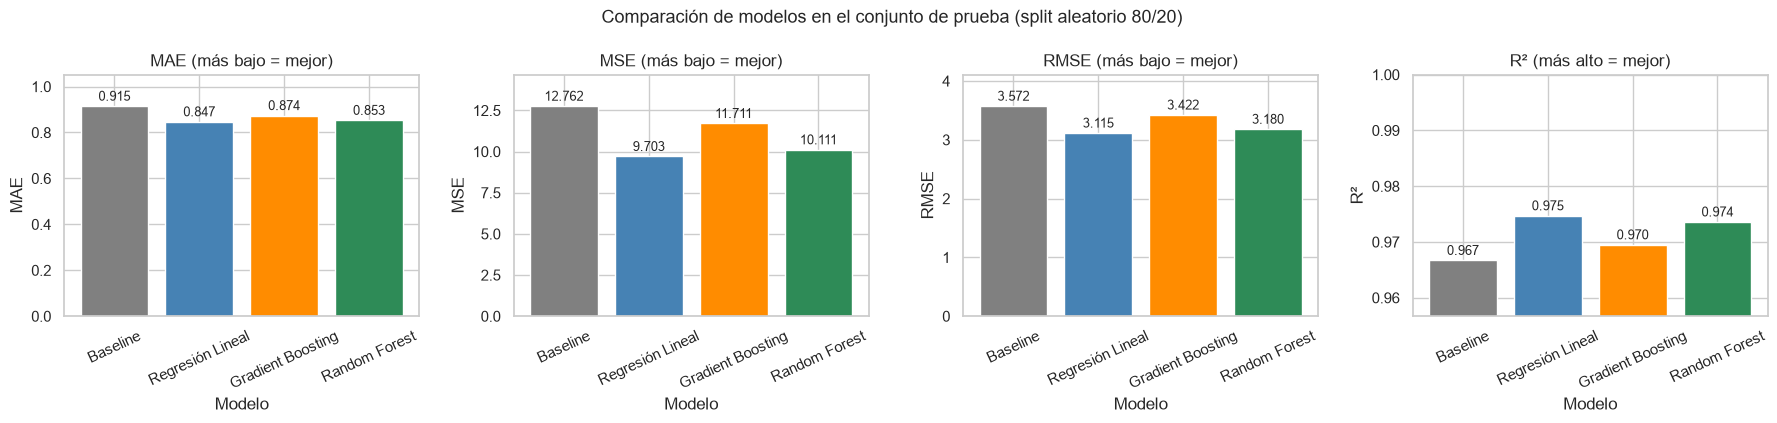

In [14]:
tabla = pd.DataFrame(resultados)
tabla_final = tabla[tabla["Modelo"].isin([
    "Baseline (mes anterior)", "Regresión Lineal (pred. ≥ 0)", "Gradient Boosting (pred. ≥ 0)", "Random Forest"
])].reset_index(drop=True)
tabla_final["Mejora MAE vs baseline"] = (1 - tabla_final["MAE"] / tabla_final.loc[0, "MAE"]).map("{:.1%}".format)
display(tabla_final)

fig, axes = plt.subplots(1, 4, figsize=(18, 4.3))
colores = ["gray", "steelblue", "darkorange", "seagreen"]
nombres_cortos = (tabla_final["Modelo"].str.replace(" (pred. ≥ 0)", "", regex=False)
                  .str.replace(" (mes anterior)", "", regex=False))
for ax, metrica in zip(axes, ["MAE", "MSE", "RMSE", "R²"]):
    barras = ax.bar(nombres_cortos, tabla_final[metrica], color=colores)
    ax.bar_label(barras, fmt="%.3f", fontsize=9, padding=2)
    ax.set_title(metrica + (" (más alto = mejor)" if metrica == "R²" else " (más bajo = mejor)"))
    ax.set_xlabel("Modelo")
    ax.set_ylabel(metrica)
    ax.tick_params(axis="x", rotation=25)
    if metrica == "R²":
        ax.set_ylim(tabla_final[metrica].min() - 0.01, 1)
    else:
        ax.set_ylim(0, tabla_final[metrica].max() * 1.15)
plt.suptitle("Comparación de modelos en el conjunto de prueba (split aleatorio 80/20)", fontsize=13)
plt.tight_layout(); plt.show()

**Insight:** los tres modelos superan al baseline en todas las métricas, pero la mejora es moderada (entre 4,5 % y 7,4 % menos error absoluto): el mes anterior ya contiene la mayor parte de la señal. La **Regresión Lineal es la mejor en las cuatro métricas** (MAE 0,847, MSE 9,70, RMSE 3,12, R² 0,975). Random Forest queda muy cerca (MAE 0,853) y Gradient Boosting tercero. Que el modelo más simple gane indica que la relación entre "cómo vienen los últimos meses" y "qué pasará el próximo" es **casi lineal**: los modelos de árboles no encuentran patrones extra que justifiquen su complejidad.

## 9. Validación adicional — ¿y si predecimos el **futuro** de verdad?

El `train_test_split` aleatorio mezcla meses de todos los años: el modelo puede entrenar con datos de 2023 y probar en 2019. En la vida real **solo se conoce el pasado**. Por eso hacemos una segunda prueba más exigente y realista:

- **Entrenar** con el periodo 2012 – 2024.
- **Probar** con 2025 – 2026 (meses que el modelo no ha visto y que son *posteriores* al entrenamiento).

Usamos la columna `CONJUNTO` que ya traía el dataset. Los tres modelos se reentrenan con la misma configuración. Esta sección es complementaria; la evaluación principal del trabajo es la del split 80/20.

In [15]:
es_train = (df["CONJUNTO"] == "train").values
Xt_tr, Xt_te = X[es_train], X[~es_train]
yt_tr, yt_te = y[es_train], y[~es_train]
print(f"Train (2012-2024): {len(Xt_tr):,} filas | Test (2025-2026): {len(Xt_te):,} filas")

lin_t = Pipeline([("escalador", StandardScaler()), ("regresion", LinearRegression())]).fit(Xt_tr, yt_tr)
gb_t = GradientBoostingRegressor(n_estimators=200, learning_rate=0.1, max_depth=4,
                                 subsample=0.8, random_state=SEMILLA).fit(Xt_tr, yt_tr)
rf_t = RandomForestRegressor(n_estimators=200, min_samples_leaf=5, max_features=0.5,
                             n_jobs=-1, random_state=SEMILLA).fit(Xt_tr, yt_tr)

res_temporal = pd.DataFrame([
    evaluar("Baseline (mes anterior)", yt_te, Xt_te["MOTOS_LAG1"]),
    evaluar("Regresión Lineal", yt_te, np.clip(lin_t.predict(Xt_te), 0, None)),
    evaluar("Gradient Boosting", yt_te, np.clip(gb_t.predict(Xt_te), 0, None)),
    evaluar("Random Forest", yt_te, rf_t.predict(Xt_te)),
])
display(res_temporal)

Train (2012-2024): 162,552 filas | Test (2025-2026): 19,798 filas


,Modelo,MAE,MSE,RMSE,R²
0,Baseline (mes anterior),1.0685,23.3177,4.8288,0.9467
1,Regresión Lineal,0.9684,15.7492,3.9685,0.9640
2,Gradient Boosting,0.9851,19.5446,4.4209,0.9553
3,Random Forest,0.9765,17.6970,4.2068,0.9596


**Insight:** al predecir de verdad el futuro (2025–2026) con modelos entrenados hasta 2024, todos los errores suben, como es esperable, pero **el orden se mantiene**: Regresión Lineal (MAE 0,968), Random Forest (0,977), Gradient Boosting (0,985) y baseline (1,069). En esta prueba la ventaja de los modelos sobre el baseline crece (la lineal reduce el MSE de 23,3 a 15,7, un 32 % menos). Que la Regresión Lineal gane en las dos validaciones da confianza en que su ventaja no es casualidad del split aleatorio.

## 10. Modelo 4 (no supervisado) — K-Means: segmentación de municipios

**Pregunta:** ¿hay **grupos de municipios** con un comportamiento parecido del hurto de motos? Si los hay, la Policía podría diseñar una estrategia por grupo en lugar de una por cada uno de los 1.042 municipios.

**Qué agrupamos:** cada punto es **un municipio** (no un municipio-mes). Describimos su perfil con 5 variables calculadas **solo con el periodo de entrenamiento (2012 – 2024)**, para no mirar los meses que usamos como prueba:

| Variable | Qué mide |
|---|---|
| `volumen_log` | promedio mensual de motos hurtadas, en escala log(1 + x) (para que Bogotá no aplaste a los demás) |
| `pct_meses_cero` | % de meses sin ningún hurto de moto |
| `variabilidad` | coeficiente de variación mensual (desv. estándar / media): qué tan irregular es |
| `tendencia` | cambio entre el promedio de 2012–2014 y el de 2022–2024, en escala log (positivo = crece) |
| `pct_autos` | % de los hurtos de vehículos que son de automotores |

**Escalado:** K-Means mide distancias, así que las variables deben estar en la misma escala. El `StandardScaler` va **dentro de un `Pipeline`** con el K-Means, de modo que se ajusta con los mismos datos que se agrupan.

In [16]:
hist_train = df[df["CONJUNTO"] == "train"]       # solo 2012-2024

def perfil_municipio(g):
    """Perfil del hurto de un municipio (una fila por municipio) calculado con su serie mensual."""
    motos, autos = g["MOTOS"], g["AUTOS"]
    inicio = motos[g["ANIO"].between(2012, 2014)].mean()
    final = motos[g["ANIO"].between(2022, 2024)].mean()
    return pd.Series({
        "volumen_log": np.log1p(motos.mean()),
        "pct_meses_cero": (motos == 0).mean() * 100,
        "variabilidad": motos.std() / motos.mean() if motos.mean() > 0 else 0.0,
        "tendencia": np.log1p(final) - np.log1p(inicio),
        "pct_autos": autos.sum() / (motos.sum() + autos.sum()) * 100 if (motos.sum() + autos.sum()) > 0 else 0.0,
        "prom_motos_mes": motos.mean(),               # solo para describir los grupos (no entra al K-Means)
    })

perfiles = hist_train.groupby("LLAVE_MUN").apply(perfil_municipio)
VARS_CLUSTER = ["volumen_log", "pct_meses_cero", "variabilidad", "tendencia", "pct_autos"]
print(f"Municipios a segmentar: {len(perfiles):,}")
perfiles[VARS_CLUSTER].describe().round(2)

Municipios a segmentar: 1,042


,volumen_log,pct_meses_cero,variabilidad,tendencia,pct_autos
count,1042.00,1042.00,1042.00,1042.00,1042.00
mean,0.48,70.40,3.35,0.22,16.80
std,0.76,30.45,2.88,0.31,15.85
min,0.00,0.00,0.00,-0.68,0.00
25%,0.06,54.49,1.36,0.03,4.01
50%,0.18,83.33,2.41,0.12,13.35
75%,0.55,94.87,4.32,0.34,25.00
max,6.05,100.00,12.49,2.08,100.00


### 10.1 ¿Cuántos grupos? Método del codo, Silhouette y Davies-Bouldin
Probamos de 2 a 8 grupos (`k`) y miramos tres criterios:
- **Inercia (codo):** suma de distancias de cada municipio al centro de su grupo. Siempre baja al subir `k`; buscamos el "codo" donde deja de bajar mucho.
- **Silhouette Score** (de −1 a 1, **más alto = mejor**): qué tan cerca está cada municipio de su grupo frente al grupo vecino.
- **Davies-Bouldin** (desde 0, **más bajo = mejor**): qué tan compactos y separados están los grupos.

,k,Inercia,Silhouette,Davies-Bouldin,Tamaño del grupo más pequeño
0,2,3231.452,0.403,1.068,297
1,3,2583.922,0.316,1.181,208
2,4,2061.252,0.305,1.017,162
3,5,1715.740,0.335,1.008,75
4,6,1460.386,0.317,1.015,66
5,7,1290.128,0.323,0.952,37
6,8,1150.127,0.326,0.970,37


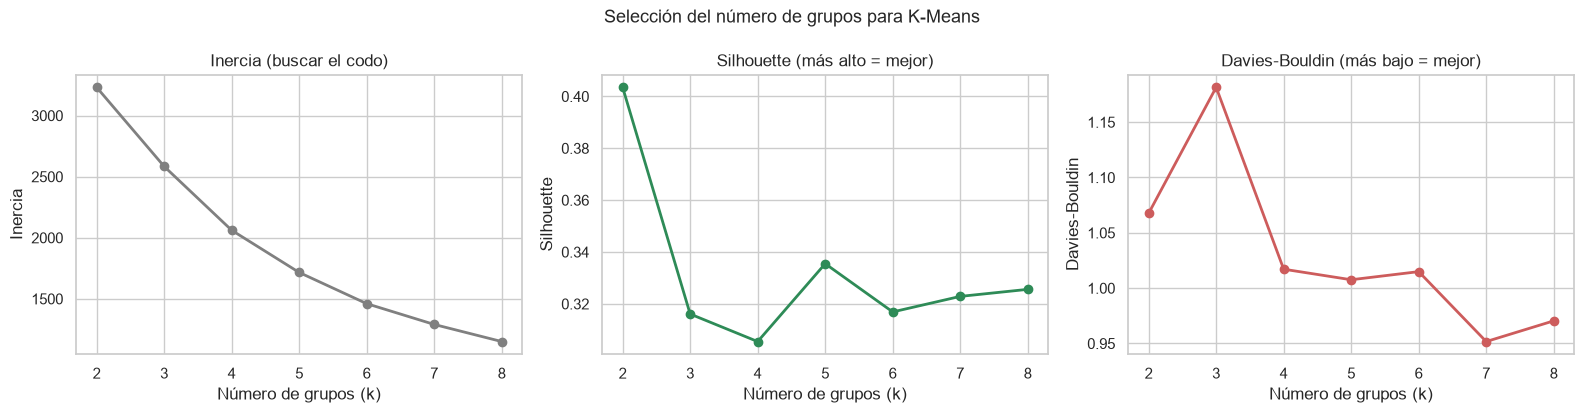

In [17]:
pruebas = []
for k in range(2, 9):
    pipe_k = Pipeline([("escalador", StandardScaler()),
                       ("kmeans", KMeans(n_clusters=k, n_init=20, random_state=SEMILLA))])
    etiquetas_k = pipe_k.fit_predict(perfiles[VARS_CLUSTER])
    Z = pipe_k.named_steps["escalador"].transform(perfiles[VARS_CLUSTER])
    pruebas.append({"k": k,
                    "Inercia": pipe_k.named_steps["kmeans"].inertia_,
                    "Silhouette": silhouette_score(Z, etiquetas_k),
                    "Davies-Bouldin": davies_bouldin_score(Z, etiquetas_k),
                    "Tamaño del grupo más pequeño": np.bincount(etiquetas_k).min()})
pruebas = pd.DataFrame(pruebas)
display(pruebas.round(3))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for ax, col, color, nota in [(axes[0], "Inercia", "gray", "buscar el codo"),
                             (axes[1], "Silhouette", "seagreen", "más alto = mejor"),
                             (axes[2], "Davies-Bouldin", "indianred", "más bajo = mejor")]:
    ax.plot(pruebas["k"], pruebas[col], marker="o", color=color, lw=2)
    ax.set_title(f"{col} ({nota})")
    ax.set_xlabel("Número de grupos (k)")
    ax.set_ylabel(col)
    ax.set_xticks(pruebas["k"])
plt.suptitle("Selección del número de grupos para K-Means", fontsize=13)
plt.tight_layout(); plt.show()

**Elección de k = 5.** El mejor Silhouette está en k = 2 (0,403), pero solo separa "municipios con hurto" de "municipios sin hurto", algo que ya sabíamos. Entre las opciones con más detalle, **k = 5 mejora a k = 4 en los dos criterios** (Silhouette 0,335 frente a 0,305; Davies-Bouldin 1,008 frente a 1,017) y coincide con la zona donde la curva de inercia empieza a aplanarse. Con k = 7 u 8 aparecen grupos de solo 37 municipios, difíciles de usar en una estrategia. Por eso elegimos **5 segmentos**: un equilibrio entre calidad estadística y utilidad para el negocio.

In [18]:
K_ELEGIDO = 5

modelo_km = Pipeline([("escalador", StandardScaler()),
                      ("kmeans", KMeans(n_clusters=K_ELEGIDO, n_init=20, random_state=SEMILLA))])
perfiles["grupo"] = modelo_km.fit_predict(perfiles[VARS_CLUSTER])
Z = modelo_km.named_steps["escalador"].transform(perfiles[VARS_CLUSTER])

sil = silhouette_score(Z, perfiles["grupo"])
dbi = davies_bouldin_score(Z, perfiles["grupo"])
print(f"K-Means con k = {K_ELEGIDO}: Silhouette = {sil:.3f} | Davies-Bouldin = {dbi:.3f}")

# Perfil promedio de cada grupo (en las unidades originales, fácil de leer)
resumen_grupos = (perfiles.groupby("grupo")
                  .agg(municipios=("volumen_log", "size"),
                       prom_motos_mes=("prom_motos_mes", "mean"),
                       pct_meses_cero=("pct_meses_cero", "mean"),
                       variabilidad=("variabilidad", "mean"),
                       tendencia=("tendencia", "mean"),
                       pct_autos=("pct_autos", "mean")))
resumen_grupos["% de las motos hurtadas"] = (perfiles.groupby("grupo")["prom_motos_mes"].sum()
                                             / perfiles["prom_motos_mes"].sum() * 100)
resumen_grupos.round(2)

K-Means con k = 5: Silhouette = 0.335 | Davies-Bouldin = 1.008


,municipios,prom_motos_mes,pct_meses_cero,variabilidad,tendencia,pct_autos,% de las motos hurtadas
grupo,,,,,,,
0,163,0.09,92.57,5.37,0.07,43.77,0.56
1,197,1.87,37.18,1.17,0.66,15.45,14.05
2,482,0.28,79.84,2.66,0.14,12.62,5.12
3,125,0.02,98.12,8.48,0.02,1.59,0.10
4,75,28.09,2.59,0.55,0.30,13.92,80.17


In [19]:
# Ejemplos de municipios de cada grupo (los de mayor volumen)
for gr, sub in perfiles.sort_values("prom_motos_mes", ascending=False).groupby("grupo"):
    ejemplos = ", ".join(m.split(" | ")[1].title() for m in sub.index[:6])
    print(f"Grupo {gr} ({len(sub)} municipios): {ejemplos}")

Grupo 0 (163 municipios): Arauquita, Albania, Hatonuevo, Inza, Distraccion, Cota
Grupo 1 (197 municipios): Soacha, Candelaria, Copacabana, Apartado, Timbio, Giron
Grupo 2 (482 municipios): Saravena, La Union, Melgar, Tierralta, Puerto Boyaca, Quimbaya
Grupo 3 (125 municipios): Valle De San Jose, Providencia, Olaya, Tasco, Funes, Union Panamericana
Grupo 4 (75 municipios): Medellin, Bogota D.C., Cali, Popayan, Barranquilla, Cucuta


**Nombre de cada segmento.** Con la tabla de perfiles damos a cada grupo un nombre de negocio. Los nombres se asignan **según el volumen promedio del grupo** (de mayor a menor), no según el número de etiqueta, para que no cambien si K-Means numera los grupos en otro orden:

| Segmento | Rasgo principal |
|---|---|
| **Grandes ciudades** | 75 municipios, ≈ 28 motos/mes, casi nunca un mes en cero; concentran el **80 %** de las motos hurtadas |
| **Intermedios en crecimiento** | 197 municipios, ≈ 1,9 motos/mes y la **tendencia más alta** (el hurto casi se duplicó entre 2012–14 y 2022–24) |
| **Pequeños con hurto ocasional** | 482 municipios (el grupo más grande), ≈ 0,3 motos/mes, 80 % de meses en cero |
| **Pequeños con más hurto de autos** | 163 municipios con pocos casos, pero donde **44 %** de los vehículos hurtados son automotores |
| **Casi sin hurto** | 125 municipios con 98 % de meses en cero |

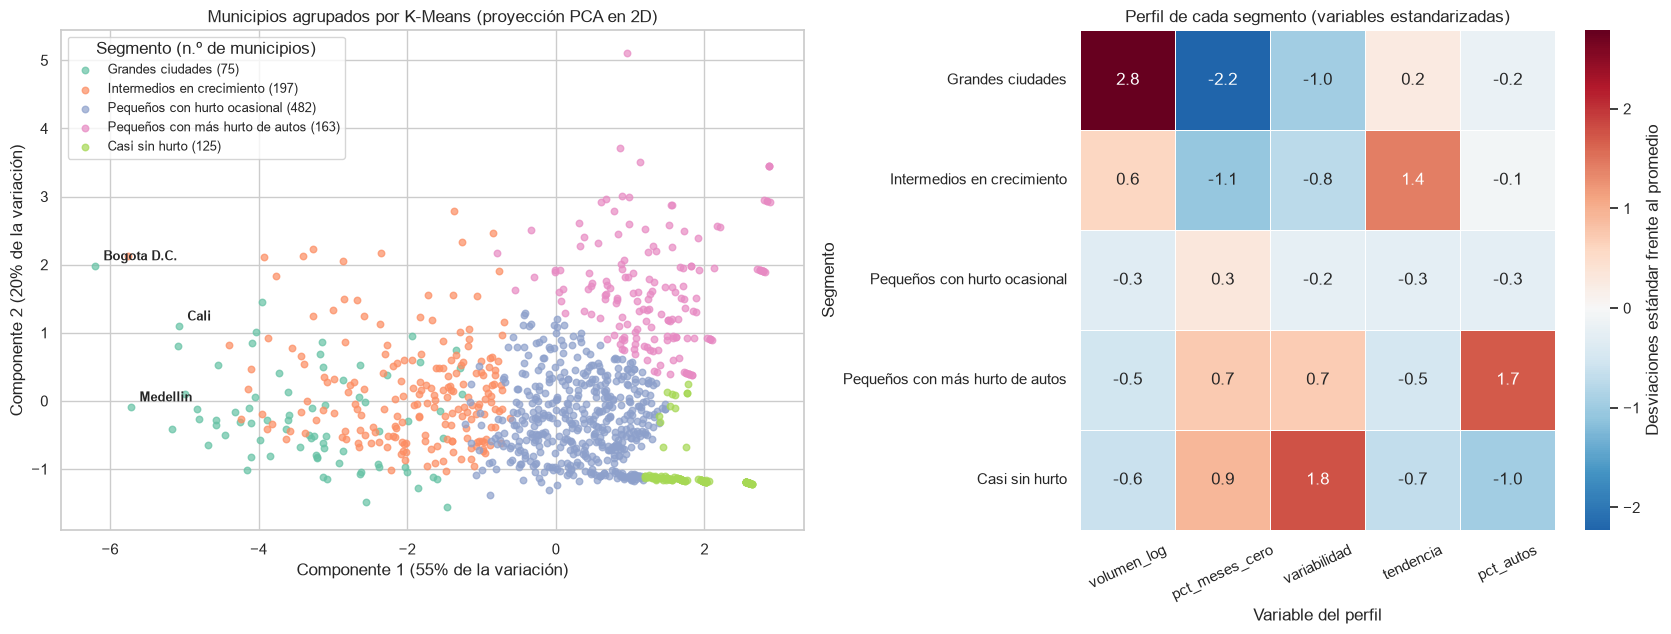

In [20]:
NOMBRES_GRUPOS = dict(zip(resumen_grupos["prom_motos_mes"].sort_values(ascending=False).index,   # nombres según el volumen del grupo
                      ["Grandes ciudades", "Intermedios en crecimiento", "Pequeños con hurto ocasional",
                       "Pequeños con más hurto de autos", "Casi sin hurto"]))
perfiles["segmento"] = perfiles["grupo"].map(NOMBRES_GRUPOS)

# PCA solo para DIBUJAR los 5 ejes en 2 dimensiones (el K-Means se hizo con las 5 variables)
pca = PCA(n_components=2, random_state=SEMILLA)
P = pca.fit_transform(Z)
paleta = dict(zip(NOMBRES_GRUPOS.values(), sns.color_palette("Set2", K_ELEGIDO)))

fig, axes = plt.subplots(1, 2, figsize=(17, 6.5), gridspec_kw={"width_ratios": [1.25, 1]})
ax = axes[0]
for seg, color in paleta.items():
    m = (perfiles["segmento"] == seg).values
    ax.scatter(P[m, 0], P[m, 1], s=22, alpha=0.7, color=color, label=f"{seg} ({m.sum()})")
for llave in perfiles.nlargest(3, "prom_motos_mes").index:
    i = perfiles.index.get_loc(llave)
    ax.annotate(llave.split(" | ")[1].title(), P[i], xytext=(6, 4), textcoords="offset points", fontsize=9, fontweight="bold")
ax.set_title("Municipios agrupados por K-Means (proyección PCA en 2D)")
ax.set_xlabel(f"Componente 1 ({pca.explained_variance_ratio_[0]:.0%} de la variación)")
ax.set_ylabel(f"Componente 2 ({pca.explained_variance_ratio_[1]:.0%} de la variación)")
ax.legend(title="Segmento (n.º de municipios)", fontsize=9)

# Perfil de cada segmento: promedio de cada variable estandarizada (0 = promedio de todos los municipios)
ax = axes[1]
perfil_z = pd.DataFrame(Z, columns=VARS_CLUSTER, index=perfiles.index).groupby(perfiles["segmento"]).mean()
perfil_z = perfil_z.loc[list(NOMBRES_GRUPOS.values())]
sns.heatmap(perfil_z, annot=True, fmt=".1f", cmap="RdBu_r", center=0, linewidths=0.5, ax=ax,
            cbar_kws={"label": "Desviaciones estándar frente al promedio"})
ax.set_title("Perfil de cada segmento (variables estandarizadas)")
ax.set_xlabel("Variable del perfil")
ax.set_ylabel("Segmento")
ax.tick_params(axis="x", rotation=25)
plt.tight_layout(); plt.show()

**Insight:** K-Means encuentra 5 perfiles claros (Silhouette = 0,335, Davies-Bouldin = 1,008). El eje horizontal del PCA ordena a los municipios por **volumen**: a la izquierda Bogotá, Medellín y Cali, a la derecha los municipios casi sin hurto. El vertical separa a los que tienen **más hurto de autos**. Para el negocio, el hallazgo más útil es el grupo **"Intermedios en crecimiento"**: 197 municipios (Soacha, Copacabana, Apartadó, Girón, Piedecuesta…) que todavía no son grandes ciudades, pero donde el hurto de motos casi se duplicó en 10 años. Son candidatos a **prevención temprana**, antes de que alcancen la escala de las capitales. Las grandes ciudades (75 municipios, 80 % de los casos) siguen siendo el foco de control.

### 10.2 ¿En qué segmentos se equivocan más los modelos?
Unimos el segmento de cada municipio con las predicciones del conjunto de prueba (split 80/20). Así respondemos la pregunta que quedaba abierta: **¿el error depende del tamaño y del tipo de municipio?**

,filas de test,motos reales prom.,Baseline,Regresión Lineal,Gradient Boosting,Random Forest
segmento,,,,,,
Grandes ciudades,2621,27.970,6.129,5.377,5.659,5.486
Intermedios en crecimiento,6856,1.889,1.407,1.212,1.205,1.215
Pequeños con hurto ocasional,17025,0.280,0.387,0.404,0.405,0.403
Pequeños con más hurto de autos,5673,0.098,0.154,0.204,0.227,0.197
Casi sin hurto,4295,0.020,0.045,0.101,0.140,0.097


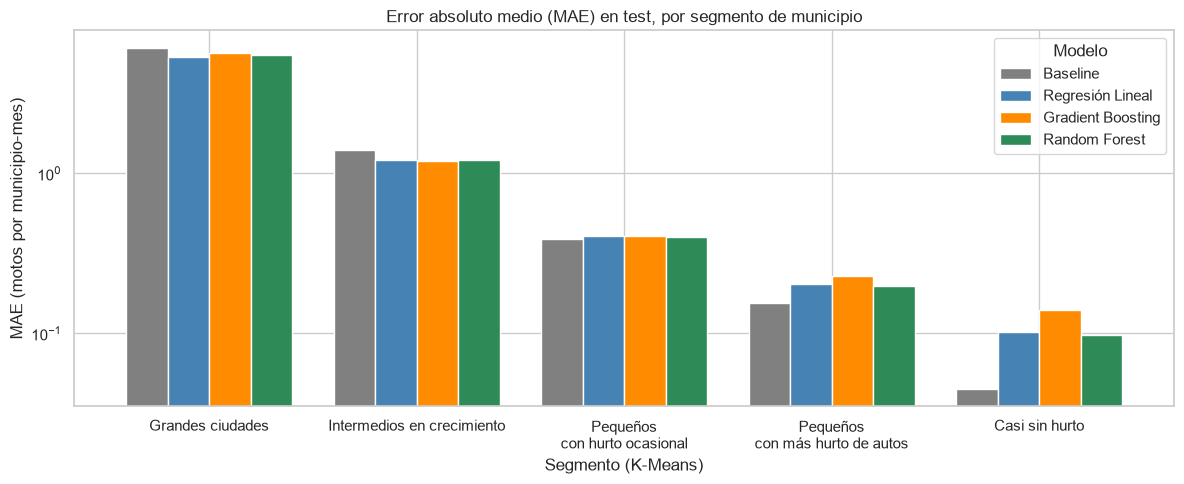

In [21]:
seg_test = df.loc[X_test.index, "LLAVE_MUN"].map(perfiles["segmento"])
error_seg = pd.DataFrame({
    "segmento": seg_test.values,
    "real": y_test.values,
    "Baseline": X_test["MOTOS_LAG1"].values,
    "Regresión Lineal": y_pred_lin_0,
    "Gradient Boosting": y_pred_gb_0,
    "Random Forest": y_pred_rf,
})
mae_seg = (error_seg.groupby("segmento")
           .apply(lambda d: pd.Series({m: mean_absolute_error(d["real"], d[m])
                                       for m in ["Baseline", "Regresión Lineal", "Gradient Boosting", "Random Forest"]}))
           .loc[list(NOMBRES_GRUPOS.values())])
mae_seg.insert(0, "filas de test", error_seg["segmento"].value_counts().reindex(mae_seg.index))
mae_seg.insert(1, "motos reales prom.", error_seg.groupby("segmento")["real"].mean().reindex(mae_seg.index))
display(mae_seg.round(3))

ax = mae_seg[["Baseline", "Regresión Lineal", "Gradient Boosting", "Random Forest"]].plot.bar(
    figsize=(12, 5), color=["gray", "steelblue", "darkorange", "seagreen"], width=0.8)
ax.set_title("Error absoluto medio (MAE) en test, por segmento de municipio")
ax.set_xlabel("Segmento (K-Means)")
ax.set_ylabel("MAE (motos por municipio-mes)")
ax.set_yscale("log")
ax.set_xticklabels([s.replace(" con ", "\ncon ") for s in mae_seg.index], rotation=0)
ax.legend(title="Modelo")
plt.tight_layout(); plt.show()

**Insight:** el error de los modelos depende mucho del segmento. En las **grandes ciudades** y los **intermedios en crecimiento**, los tres modelos mejoran claramente al baseline (la lineal baja el MAE de 6,13 a 5,38 en grandes ciudades y de 1,41 a 1,21 en intermedios): ahí está el valor del modelo. En los municipios **pequeños o casi sin hurto** pasa lo contrario: los modelos predicen valores pequeños pero positivos (por ejemplo, 0,1 motos) donde casi siempre hay 0, y quedan **peor que el baseline** (en "Casi sin hurto", 0,10 frente a 0,05). Como mejora futura convendría un enfoque por segmento: modelo para los municipios con hurto frecuente y regla simple ("igual al mes anterior") para los demás.

## 11. Conclusiones y modelo elegido

*(Los valores citados corresponden a la ejecución con `random_state=42`.)*

### Tabla resumen (conjunto de prueba)

| Modelo | MAE | MSE | RMSE | R² | MAE en prueba de futuro (2025–26) |
|---|---|---|---|---|---|
| Baseline (mes anterior) | 0,915 | 12,76 | 3,57 | 0,967 | 1,069 |
| **Regresión Lineal** | **0,847** | **9,70** | **3,12** | **0,975** | **0,968** |
| Gradient Boosting | 0,874 | 11,71 | 3,42 | 0,970 | 0,985 |
| Random Forest | 0,853 | 10,11 | 3,18 | 0,974 | 0,977 |

| Modelo no supervisado | k | Silhouette | Davies-Bouldin |
|---|---|---|---|
| K-Means (municipios) | 5 | 0,335 | 1,008 |

### Conclusiones
1. **Sí es posible predecir** los hurtos de motos del siguiente mes: los tres modelos explican cerca del **97 % de la variación** (R² ≈ 0,97) y se equivocan, en promedio, en **menos de 1 moto por municipio-mes**.
2. **Los tres modelos superan al baseline**, pero la mejora es moderada (4,5 % a 7,4 % en MAE): el comportamiento reciente ya contiene casi toda la señal.
3. **La variable que más pesa es el historial reciente** (promedio de 3 meses y mes anterior), tanto en la lineal como en los modelos de árboles. Calendario y departamento aportan poco.
4. **La segmentación con K-Means** muestra 5 perfiles de municipio y explica dónde aporta el modelo: en las grandes ciudades e intermedios mejora claramente al baseline, mientras que en los municipios casi sin hurto no.
5. **Limitación:** el dataset está dominado por municipios con pocos hurtos (70 % de meses en 0), por eso el MAE luce bajo; el RMSE, más alto, refleja los errores en las grandes ciudades.

### Modelo elegido: **Regresión Lineal**
- **Por precisión:** es la mejor en las cuatro métricas del split 80/20 **y** en la prueba de futuro 2025–2026, así que su ventaja no depende de cómo se partieron los datos.
- **Por interpretabilidad:** cada coeficiente se explica en palabras ("si el promedio de los últimos 3 meses sube, el pronóstico sube en tanto"), algo que un tomador de decisiones puede auditar. Random Forest y Gradient Boosting son cajas negras en comparación.
- **Por simplicidad:** entrena en segundos, no tiene hiperparámetros que ajustar y es fácil de poner en producción.
- **Matiz:** puede dar predicciones negativas (16 % de los casos en test), que se corrigen recortando en 0; con ese ajuste es la versión reportada. Random Forest queda como **alternativa** cercana si se quiere un modelo que nunca prediga negativos.

### Posibles mejoras
- Ajustar hiperparámetros de Random Forest y Gradient Boosting con `GridSearchCV` y validación temporal (`TimeSeriesSplit`).
- Modelar en escala logarítmica o con un modelo de conteo (Poisson), más adecuado para una variable con tantos ceros.
- Entrenar un modelo por segmento de K-Means o usar el segmento como variable predictora.

### Checklist de requisitos
- [x] `train_test_split` 80/20 aplicado
- [x] Métricas (MSE, RMSE, R², MAE) calculadas solo sobre el conjunto de **test**
- [x] Escalado ajustado **solo con train** (dentro de `Pipeline`), nunca antes del split
- [x] Sin fuga de información en las variables (se excluyeron `MOTOS_LOG`, `AUTOS`, `*_ESC`, etc.)
- [x] Tres modelos supervisados: Regresión Lineal, Gradient Boosting y Random Forest, con tabla comparativa
- [x] Un modelo no supervisado: K-Means con Silhouette Score y Davies-Bouldin
- [x] Justificación del modelo elegido